## 1. import neccessary libraries

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, precision_score, recall_score, f1_score
import warnings
warnings.filterwarnings('ignore')

# Styling for plots
plt.style.use('default')
sns.set_palette("husl")
plt.rcParams['font.size'] = 10
print("🚀 Starting Credit Scoring Model with Correct Datasets...")

🚀 Starting Credit Scoring Model with Correct Datasets...


## 2. Load The dataset

In [32]:
print("📂 Loading datasets...")
app_df = pd.read_csv('application_record.csv')
credit_df = pd.read_csv('credit_record.csv')

print(f"📊 Application data shape: {app_df.shape}")
print(f"📊 Credit record data shape: {credit_df.shape}")

# =====================
# 🔍 Explore Both Datasets
# =====================
print("\n" + "="*50)
print("🔍 Exploring Both Datasets")
print("="*50)

print("👀 Application Data Head:")
print(app_df.head())

print("\n👀 Credit Record Data Head:")
print(credit_df.head())

print("\n📋 Application Data Info:")
print(app_df.info())

print("\n📋 Credit Record Data Info:")
print(credit_df.info())

print("\n🎯 Credit Status Distribution:")
print(credit_df['STATUS'].value_counts().sort_index())

📂 Loading datasets...
📊 Application data shape: (438557, 18)
📊 Credit record data shape: (1048575, 3)

🔍 Exploring Both Datasets
👀 Application Data Head:
        ID CODE_GENDER FLAG_OWN_CAR FLAG_OWN_REALTY  CNT_CHILDREN  \
0  5008804           M            Y               Y             0   
1  5008805           M            Y               Y             0   
2  5008806           M            Y               Y             0   
3  5008808           F            N               Y             0   
4  5008809           F            N               Y             0   

   AMT_INCOME_TOTAL      NAME_INCOME_TYPE            NAME_EDUCATION_TYPE  \
0          427500.0               Working               Higher education   
1          427500.0               Working               Higher education   
2          112500.0               Working  Secondary / secondary special   
3          270000.0  Commercial associate  Secondary / secondary special   
4          270000.0  Commercial associate  Secondar

## 3. Create Target Variable from Credit  Records

In [35]:
print("\n" + "="*50)
print("🎯 Creating Target Variable from Credit History")
print("="*50)

def create_credit_target(credit_data):
    """
    Create target variable based on credit history:
    - Good Credit (1): No significant delays (C, X, 0)
    - Bad Credit (0): Significant delays (1, 2, 3, 4, 5)
    """
    # Group by client ID and check their worst status
    client_status = credit_data.groupby('ID')['STATUS'].agg(['min', 'count']).reset_index()
    client_status.columns = ['ID', 'worst_status', 'record_count']
    
    # Define good/bad credit based on worst status
    client_status['TARGET'] = client_status['worst_status'].apply(
        lambda x: 1 if x in ['C', 'X', '0'] else 0
    )
    
    return client_status[['ID', 'TARGET', 'record_count', 'worst_status']]

#Create target variable
target_df = create_credit_target(credit_df)

print("🎯 Target Distribution:")
print(target_df['TARGET'].value_counts())
print(f"✅ Good Credit Rate: {target_df['TARGET'].mean():.2%}")

print("\n📊 Clients by Worst Status:")
print(target_df['worst_status'].value_counts())




🎯 Creating Target Variable from Credit History
🎯 Target Distribution:
TARGET
1    45933
0       52
Name: count, dtype: int64
✅ Good Credit Rate: 99.89%

📊 Clients by Worst Status:
worst_status
0    39980
X     4536
C     1417
1       43
4        5
2        2
5        1
3        1
Name: count, dtype: int64


## 4. Merge Datasets

In [36]:
print("\n" + "="*50)
print("🔗 Merging Application and Credit Data")
print("="*50)

# Merge application data with target
df = pd.merge(app_df, target_df, on='ID', how='inner')

print(f"📊 Merged dataset shape: {df.shape}")
print(f"🔍 Missing values: {df.isnull().sum().sum()}")

print("\n👀 Merged Data Head:")
print(df.head())


🔗 Merging Application and Credit Data
📊 Merged dataset shape: (36457, 21)
🔍 Missing values: 11323

👀 Merged Data Head:
        ID CODE_GENDER FLAG_OWN_CAR FLAG_OWN_REALTY  CNT_CHILDREN  \
0  5008804           M            Y               Y             0   
1  5008805           M            Y               Y             0   
2  5008806           M            Y               Y             0   
3  5008808           F            N               Y             0   
4  5008809           F            N               Y             0   

   AMT_INCOME_TOTAL      NAME_INCOME_TYPE            NAME_EDUCATION_TYPE  \
0          427500.0               Working               Higher education   
1          427500.0               Working               Higher education   
2          112500.0               Working  Secondary / secondary special   
3          270000.0  Commercial associate  Secondary / secondary special   
4          270000.0  Commercial associate  Secondary / secondary special   

     NAM

## 5. Data  Analysis

In [37]:
print("\n" + "="*50)
print("📊 Data Analysis")
print("="*50)

# Basic statistics
print("📈 Basic Statistics for Numerical Features:")
print(df[['AMT_INCOME_TOTAL', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'record_count']].describe())

# Convert days to years for better interpretation
df['AGE'] = df['DAYS_BIRTH'] / -365
df['EMPLOYMENT_YEARS'] = df['DAYS_EMPLOYED'] / -365

# Replace unrealistic employment years (positive values indicate future employment)
df['EMPLOYMENT_YEARS'] = df['EMPLOYMENT_YEARS'].apply(lambda x: 0 if x < 0 else x)

print(f"\n📊 Final dataset shape: {df.shape}")


📊 Data Analysis
📈 Basic Statistics for Numerical Features:
       AMT_INCOME_TOTAL    DAYS_BIRTH  DAYS_EMPLOYED  record_count
count      3.645700e+04  36457.000000   36457.000000  36457.000000
mean       1.866857e+05 -15975.173382   59262.935568     21.332392
std        1.017892e+05   4200.549944  137651.334859     14.911849
min        2.700000e+04 -25152.000000  -15713.000000      1.000000
25%        1.215000e+05 -19438.000000   -3153.000000      9.000000
50%        1.575000e+05 -15563.000000   -1552.000000     18.000000
75%        2.250000e+05 -12462.000000    -408.000000     31.000000
max        1.575000e+06  -7489.000000  365243.000000     61.000000

📊 Final dataset shape: (36457, 23)


## 6. Exploratory  Data  Analysis


📈 Exploratory Data Analysis


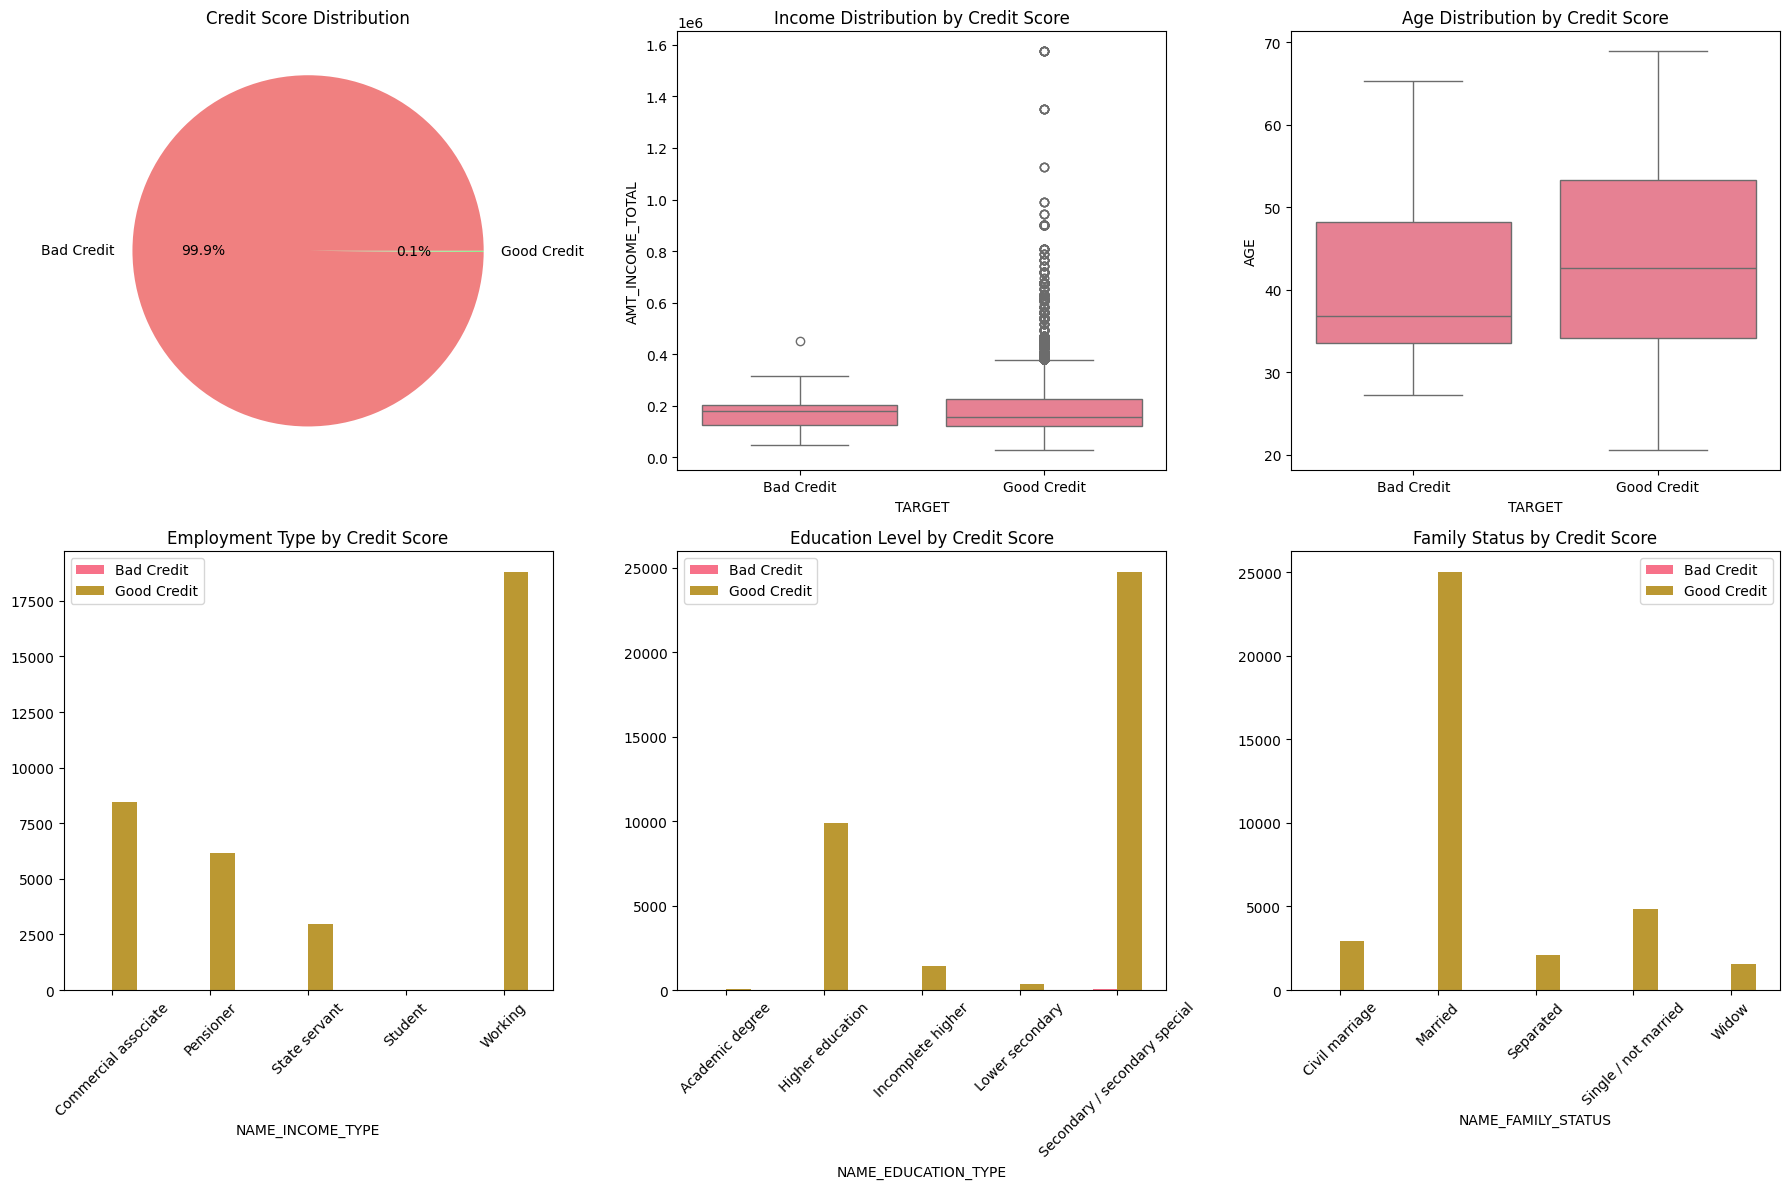

In [39]:
print("\n" + "="*50)
print("📈 Exploratory Data Analysis")
print("="*50)

# Create visualizations
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# 1. Target distribution
target_counts = df['TARGET'].value_counts()
axes[0,0].pie(target_counts.values, labels=['Bad Credit', 'Good Credit'], autopct='%1.1f%%', colors=['lightcoral', 'lightgreen'])
axes[0,0].set_title('Credit Score Distribution')

# 2. Income by credit score
sns.boxplot(data=df, x='TARGET', y='AMT_INCOME_TOTAL', ax=axes[0,1])
axes[0,1].set_title('Income Distribution by Credit Score')
axes[0,1].set_xticklabels(['Bad Credit', 'Good Credit'])

# 3. Age distribution
sns.boxplot(data=df, x='TARGET', y='AGE', ax=axes[0,2])
axes[0,2].set_title('Age Distribution by Credit Score')
axes[0,2].set_xticklabels(['Bad Credit', 'Good Credit'])

# 4. Employment type
employment_target = pd.crosstab(df['NAME_INCOME_TYPE'], df['TARGET'])
employment_target.plot(kind='bar', ax=axes[1,0])
axes[1,0].set_title('Employment Type by Credit Score')
axes[1,0].legend(['Bad Credit', 'Good Credit'])
axes[1,0].tick_params(axis='x', rotation=45)

# 5. Education level
education_target = pd.crosstab(df['NAME_EDUCATION_TYPE'], df['TARGET'])
education_target.plot(kind='bar', ax=axes[1,1])
axes[1,1].set_title('Education Level by Credit Score')
axes[1,1].legend(['Bad Credit', 'Good Credit'])
axes[1,1].tick_params(axis='x', rotation=45)

# 6. Family status
family_target = pd.crosstab(df['NAME_FAMILY_STATUS'], df['TARGET'])
family_target.plot(kind='bar', ax=axes[1,2])
axes[1,2].set_title('Family Status by Credit Score')
axes[1,2].legend(['Bad Credit', 'Good Credit'])
axes[1,2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


## 7. Data  Preprocessing

In [40]:
print("\n" + "="*50)
print("🧹 Data Preprocessing")
print("="*50)

# Drop unnecessary columns
cols_to_drop = ['ID', 'FLAG_MOBIL', 'FLAG_WORK_PHONE', 'FLAG_PHONE', 'FLAG_EMAIL', 
                'DAYS_BIRTH', 'DAYS_EMPLOYED', 'worst_status', 'record_count']
df_clean = df.drop(columns=cols_to_drop, errors='ignore')

print(f"📊 Shape after cleaning: {df_clean.shape}")

# Handle categorical variables
categorical_cols = df_clean.select_dtypes(include=['object']).columns.tolist()
print(f"📋 Categorical columns: {categorical_cols}")

label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    df_clean[col] = le.fit_transform(df_clean[col].astype(str))
    label_encoders[col] = le

# Check for missing values
print("🔍 Missing values after preprocessing:")
print(df_clean.isnull().sum())

# Prepare features and target
X = df_clean.drop('TARGET', axis=1)
y = df_clean['TARGET']

print(f"📊 Features shape: {X.shape}")
print(f"🎯 Target shape: {y.shape}")


🧹 Data Preprocessing
📊 Shape after cleaning: (36457, 14)
📋 Categorical columns: ['CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE']
🔍 Missing values after preprocessing:
CODE_GENDER            0
FLAG_OWN_CAR           0
FLAG_OWN_REALTY        0
CNT_CHILDREN           0
AMT_INCOME_TOTAL       0
NAME_INCOME_TYPE       0
NAME_EDUCATION_TYPE    0
NAME_FAMILY_STATUS     0
NAME_HOUSING_TYPE      0
OCCUPATION_TYPE        0
CNT_FAM_MEMBERS        0
TARGET                 0
AGE                    0
EMPLOYMENT_YEARS       0
dtype: int64
📊 Features shape: (36457, 13)
🎯 Target shape: (36457,)


## 8. Model Training

In [42]:
print("\n" + "="*50)
print("🤖 Model Training")
print("="*50)

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"📊 Training set: {X_train.shape}")
print(f"📊 Test set: {X_test.shape}")

# Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Initialize models
models = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42, n_estimators=100)
}

# Train and evaluate models
results = {}

for name, model in models.items():
    print(f"\n🔧 Training {name}...")
    
    if name == 'Logistic Regression':
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
        y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        y_pred_proba = model.predict_proba(X_test)[:, 1]
    
    # Calculate metrics
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_pred_proba)
    
    results[name] = {
        'precision': precision,
        'recall': recall,
        'f1_score': f1,
        'roc_auc': roc_auc,
        'model': model,
        'predictions': y_pred,
        'probabilities': y_pred_proba
    }
    
    print(f"✅ {name} Results:")
    print(f"   Precision: {precision:.4f}")
    print(f"   Recall: {recall:.4f}")
    print(f"   F1-Score: {f1:.4f}")
    print(f"   ROC-AUC: {roc_auc:.4f}")


🤖 Model Training
📊 Training set: (29165, 13)
📊 Test set: (7292, 13)

🔧 Training Logistic Regression...
✅ Logistic Regression Results:
   Precision: 0.9989
   Recall: 1.0000
   F1-Score: 0.9995
   ROC-AUC: 0.4294

🔧 Training Decision Tree...
✅ Decision Tree Results:
   Precision: 0.9989
   Recall: 0.9992
   F1-Score: 0.9990
   ROC-AUC: 0.5610

🔧 Training Random Forest...
✅ Random Forest Results:
   Precision: 0.9989
   Recall: 0.9993
   F1-Score: 0.9991
   ROC-AUC: 0.5510


## 9. Model Comparsion

In [43]:
print("\n" + "="*50)
print("📈 Model Comparison")
print("="*50)

# Create comparison table
comparison_df = pd.DataFrame({
    'Model': list(results.keys()),
    'Precision': [results[name]['precision'] for name in results],
    'Recall': [results[name]['recall'] for name in results],
    'F1-Score': [results[name]['f1_score'] for name in results],
    'ROC-AUC': [results[name]['roc_auc'] for name in results]
})

print("📊 Model Performance Comparison:")
print(comparison_df.round(4))

# Find best model
best_model_name = comparison_df.loc[comparison_df['ROC-AUC'].idxmax(), 'Model']
best_model = results[best_model_name]['model']
print(f"\n🏆 Best Model: {best_model_name}")


📈 Model Comparison
📊 Model Performance Comparison:
                 Model  Precision  Recall  F1-Score  ROC-AUC
0  Logistic Regression     0.9989  1.0000    0.9995   0.4294
1        Decision Tree     0.9989  0.9992    0.9990   0.5610
2        Random Forest     0.9989  0.9993    0.9991   0.5510

🏆 Best Model: Decision Tree


## 10. Detailed Evaluation


📊 Detailed Evaluation of Best Model
📋 Classification Report for Decision Tree:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         8
           1       1.00      1.00      1.00      7284

    accuracy                           1.00      7292
   macro avg       0.50      0.50      0.50      7292
weighted avg       1.00      1.00      1.00      7292



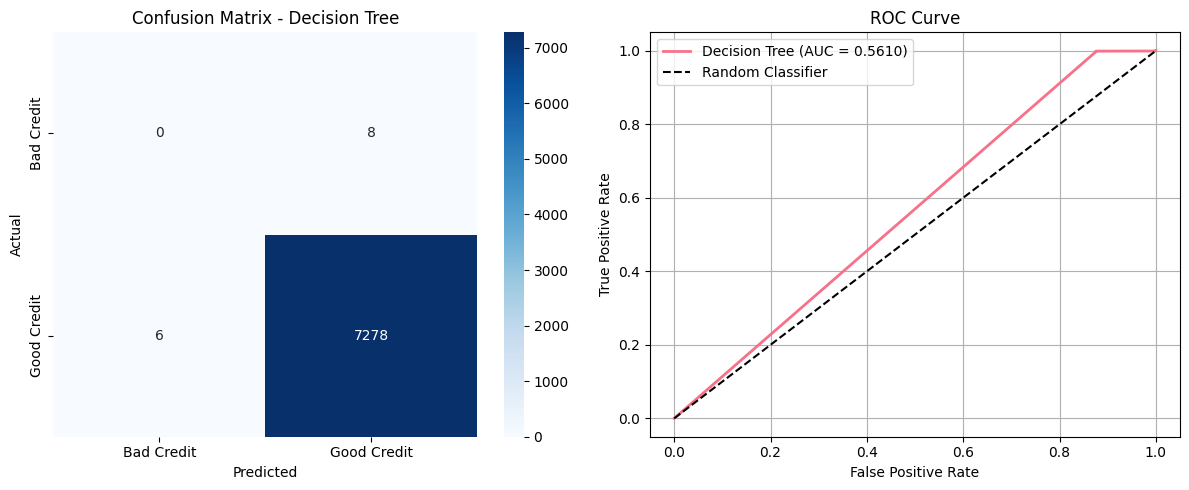

In [44]:
print("\n" + "="*50)
print("📊 Detailed Evaluation of Best Model")
print("="*50)

# Classification report
print(f"📋 Classification Report for {best_model_name}:")
print(classification_report(y_test, results[best_model_name]['predictions']))

# Confusion matrix and ROC curve
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
cm = confusion_matrix(y_test, results[best_model_name]['predictions'])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Bad Credit', 'Good Credit'], 
            yticklabels=['Bad Credit', 'Good Credit'])
plt.title(f'Confusion Matrix - {best_model_name}')
plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.subplot(1, 2, 2)
fpr, tpr, _ = roc_curve(y_test, results[best_model_name]['probabilities'])
plt.plot(fpr, tpr, label=f'{best_model_name} (AUC = {results[best_model_name]["roc_auc"]:.4f})', linewidth=2)
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## 11. Feature  Importance


💡 Feature Importance
📊 Top 10 Most Important Features:
                feature  importance
11                  AGE    0.408194
12     EMPLOYMENT_YEARS    0.339683
4      AMT_INCOME_TOTAL    0.103251
7    NAME_FAMILY_STATUS    0.074623
2       FLAG_OWN_REALTY    0.043733
0           CODE_GENDER    0.012802
9       OCCUPATION_TYPE    0.011334
10      CNT_FAM_MEMBERS    0.003310
6   NAME_EDUCATION_TYPE    0.001858
5      NAME_INCOME_TYPE    0.001212


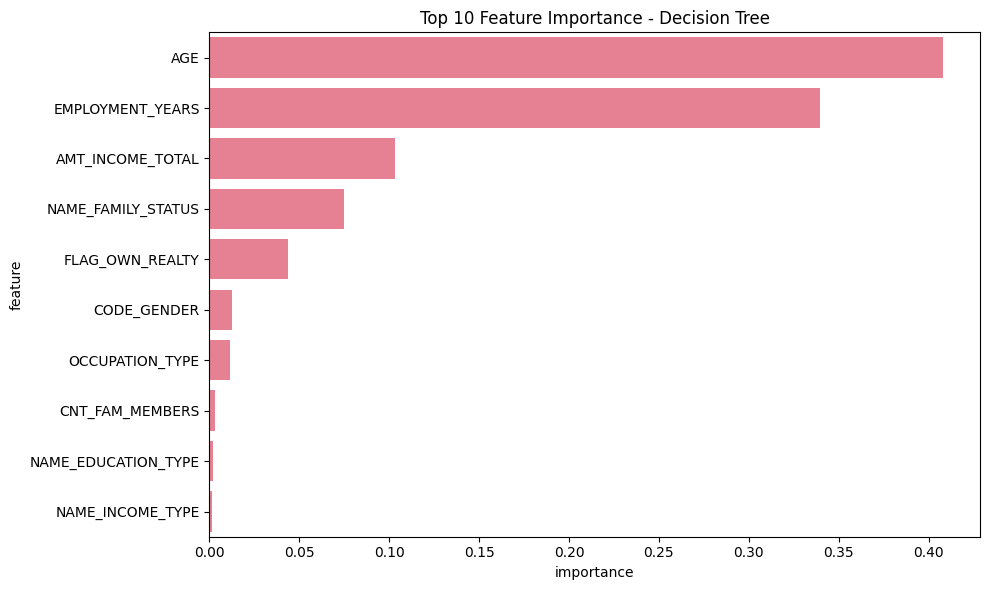

In [45]:
print("\n" + "="*50)
print("💡 Feature Importance")
print("="*50)

if hasattr(best_model, 'feature_importances_'):
    feature_importance = pd.DataFrame({
        'feature': X.columns,
        'importance': best_model.feature_importances_
    }).sort_values('importance', ascending=False)
    
    print("📊 Top 10 Most Important Features:")
    print(feature_importance.head(10))
    
    plt.figure(figsize=(10, 6))
    sns.barplot(data=feature_importance.head(10), x='importance', y='feature')
    plt.title(f'Top 10 Feature Importance - {best_model_name}')
    plt.tight_layout()
    plt.show()

## 12. Save Results

In [47]:
print("\n" + "="*50)
print("💾 Saving Results")
print("="*50)

# Save predictions
output_df = X_test.copy()
output_df['ACTUAL_TARGET'] = y_test
output_df['PREDICTED_TARGET'] = results[best_model_name]['predictions']
output_df['PREDICTION_PROBABILITY'] = results[best_model_name]['probabilities']

# Save to CSV
output_df.to_csv('credit_scoring_predictions.csv', index=False)
print("✅ Predictions saved to 'credit_scoring_predictions.csv'")

comparison_df.to_csv('model_comparison.csv', index=False)
print("✅ Model comparison saved to 'model_comparison.csv'")

# Save feature importance if available
if 'feature_importance' in locals():
    feature_importance.to_csv('feature_importance.csv', index=False)
    print("✅ Feature importance saved to 'feature_importance.csv'")

print("\n" + "="*50)
print("🎉 CREDIT SCORING MODEL COMPLETED SUCCESSFULLY!")
print("="*50)
print(f"🏆 Best Model: {best_model_name}")
print(f"📊 ROC-AUC Score: {results[best_model_name]['roc_auc']:.4f}")
print(f"🎯 F1-Score: {results[best_model_name]['f1_score']:.4f}")
print(f"📈 Precision: {results[best_model_name]['precision']:.4f}")
print(f"📈 Recall: {results[best_model_name]['recall']:.4f}")
print("="*50)


💾 Saving Results
✅ Predictions saved to 'credit_scoring_predictions.csv'
✅ Model comparison saved to 'model_comparison.csv'
✅ Feature importance saved to 'feature_importance.csv'

🎉 CREDIT SCORING MODEL COMPLETED SUCCESSFULLY!
🏆 Best Model: Decision Tree
📊 ROC-AUC Score: 0.5610
🎯 F1-Score: 0.9990
📈 Precision: 0.9989
📈 Recall: 0.9992


# Thank You